# CF-Miner: Lead time of canceled bookings

We look for segments of canceled bookings in which the share of bookings rises with lead time,
i.e. bookings made far in advance dominate. This task is the counterpart of
`lead_time_distribution.ipynb`, which looks for a falling distribution in all bookings.

**Question:** In which segments of canceled bookings do bookings made far in advance prevail?
Does this differ between the City Hotel and the Resort Hotel?

| Part | Setting |
| --- | --- |
| Attribute for histogram (A) | `lead_time_cat` |
| Condition (C) | `hotel`, `market_segment`, `customer_type`, `deposit_type` (subset, 1) |
| Condition length | 1–2 |
| Data | canceled bookings only (`is_canceled = 1`, filtered beforehand) |
| Quantifiers | `S_Up ≥ 4`, `Base ≥ 1000` |
| Aggregate function | none |

In [1]:
import pandas as pd
from cleverminer import cleverminer

df = pd.read_csv("../../data/processed/hotel_bookings_categorized.csv", dtype=str)
df = df[df["is_canceled"] == "1"]
df = df[[
    "hotel",
    "market_segment",
    "customer_type",
    "deposit_type",
    "lead_time_cat",
]]

print("Canceled bookings:", len(df))

Cleverminer version  1.2.8
Canceled bookings: 44171


## Lead time of all canceled bookings

Share of canceled bookings in each lead time category, separately for both hotels.
This is the baseline against which the found segments are compared.

In [2]:
pd.crosstab(df["lead_time_cat"], df["hotel"], normalize="columns").round(3)

hotel,City Hotel,Resort Hotel
lead_time_cat,,
1_0-7,0.039,0.052
2_8-30,0.117,0.126
3_31-90,0.251,0.256
4_91-180,0.264,0.277
5_181-365,0.270,0.271
6_365+,0.058,0.019


## CF-Miner

`lead_time_cat` has 6 ordered categories, so a histogram has at most 5 steps.
`S_Up ≥ 4` requires at least 4 consecutive increases, i.e. the share grows from `1_0-7` up to
`5_181-365`. The last category `6_365+` is small, so `S_Up = 5` (growth all the way to
`6_365+`) finds no segment. `Base ≥ 1000` requires at least 1000 canceled bookings in the segment.

In [3]:
miner = cleverminer(
    df=df,
    proc="CFMiner",
    target="lead_time_cat",
    quantifiers={
        "S_Up": 4,
        "Base": 1000,
    },
    cond={
        "attributes": [
            {"name": "hotel", "type": "subset", "minlen": 1, "maxlen": 1},
            {"name": "market_segment", "type": "subset", "minlen": 1, "maxlen": 1},
            {"name": "customer_type", "type": "subset", "minlen": 1, "maxlen": 1},
            {"name": "deposit_type", "type": "subset", "minlen": 1, "maxlen": 1},
        ],
        "minlen": 1,
        "maxlen": 2,
        "type": "con",
    },
    opts={
        "disable_progressbar": True,
    },
)

Cleverminer version 1.2.8.
Progressbar will not be shown.
Progressbar will not be shown.
Starting data preparation ...
Automatically reordering numeric categories ...
Automatically reordering numeric categories ...done
Encoding columns into bit-form...
Encoding columns into bit-form...done
Data preparation finished.
Progressbar will not be shown.
Will go for  CFMiner
Starting to mine rules.


Done. Total verifications : 43, rules 15, times: prep 0.03sec, processing 0.01sec


## Results

Overview of all rules. `BASE` is the number of canceled bookings in the segment,
`S_UP` and `S_DOWN` are the longest runs of increases and decreases in the histogram.

In [4]:
miner.print_summary()
miner.print_rulelist()


CleverMiner task processing summary:

Task type : CFMiner
Number of verifications : 43
Number of rules : 15
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


List of rules:
RULEID BASE  S_UP  S_DOWN Condition
     1 33061     4     1 hotel(City Hotel)
     2  9620     4     1 hotel(City Hotel) & market_segment(Groups)
     3  7165     4     1 hotel(City Hotel) & market_segment(Offline TA/TO)
     4 12843     4     1 hotel(City Hotel) & deposit_type(Non Refund)
     5  2473     4     1 hotel(Resort Hotel) & market_segment(Groups)
     6  1135     4     1 hotel(Resort Hotel) & market_segment(Offline TA/TO)
     7 12093     4     1 market_segment(Groups)
     8  8064     4     1 market_segment(Groups) & customer_type(Transient)
     9  9110     4     1 market_segment(Groups) & deposit_type(Non Refund)
    10  8300     4     1 market_segment(Offline TA/TO)
    11  5982     4     1 market_segment(Offline TA/TO) & customer_type(Transi

### All rules in detail

Histograms of all rules, one below another.

In [5]:
for rule_id in range(1, miner.get_rulecount() + 1):
    miner.print_rule(rule_id)



Rule id : 1

Base : 33061  Relative base : 0.748  Steps UP (consecutive) :     4  Steps DOWN (consecutive) :     1  Steps UP (any) :     4  Steps DOWN (any) :     1  Histogram maximum :  8929  Histogram minimum :  1293  Histogram relative maximum : 0.270 Histogram relative minimum : 0.039 

Condition  : hotel(City Hotel)

Categories in target variable  ['1_0-7', '2_8-30', '3_31-90', '4_91-180', '5_181-365', '6_365+']
Histogram                      [1293, 3877, 8296, 8744, 8929, 1922]



Rule id : 2

Base :  9620  Relative base : 0.218  Steps UP (consecutive) :     4  Steps DOWN (consecutive) :     1  Steps UP (any) :     4  Steps DOWN (any) :     1  Histogram maximum :  3867  Histogram minimum :    73  Histogram relative maximum : 0.402 Histogram relative minimum : 0.008 

Condition  : hotel(City Hotel) & market_segment(Groups)

Categories in target variable  ['1_0-7', '2_8-30', '3_31-90', '4_91-180', '5_181-365', '6_365+']
Histogram                      [73, 406, 1643, 2127, 3867, 1

### Histograms: City vs. Resort

Rule 1 shows all canceled bookings of the City Hotel. Rules 2 and 5 compare the Groups segment,
rules 3 and 6 the Offline TA/TO segment in the City Hotel and the Resort Hotel.

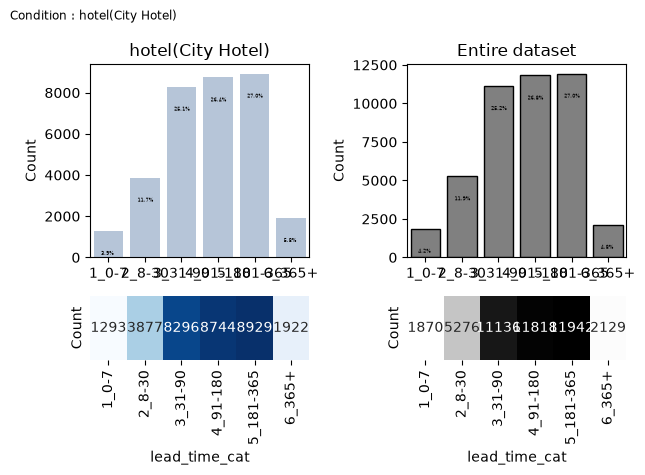

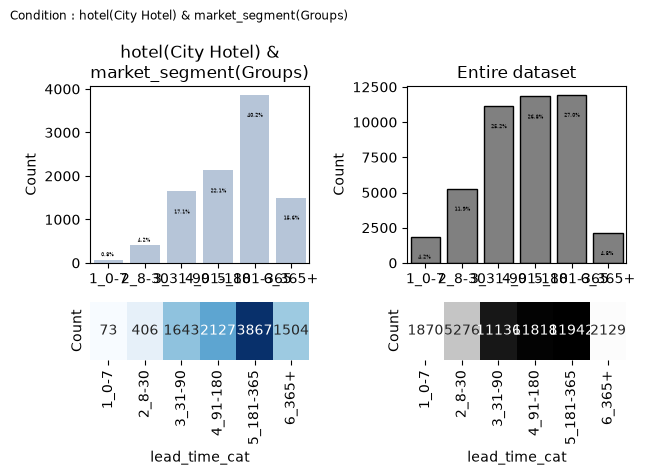

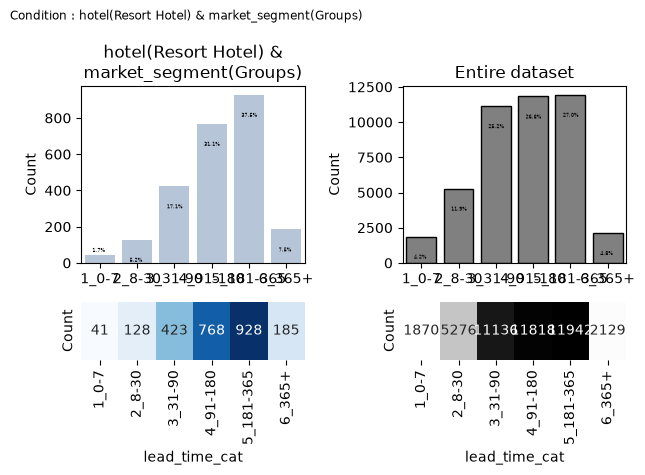

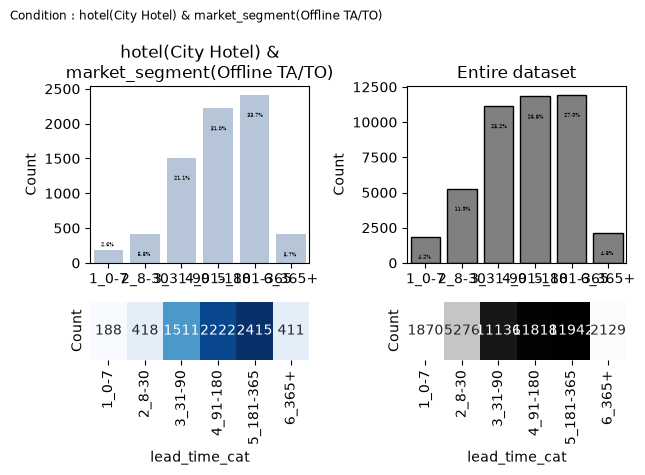

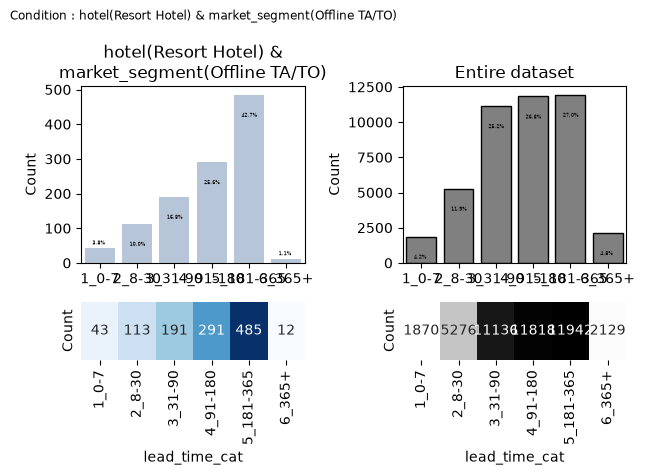

In [6]:
miner.draw_rule(1)
miner.draw_rule(2)
miner.draw_rule(5)
miner.draw_rule(3)
miner.draw_rule(6)